# 02 - Baseline training pipeline

Goal: validate the full pipeline (data -> training -> metrics -> checkpoint) end to end with a **simple, shallow CNN**, before investing time in ResNet, ViT and MedViT. If this notebook runs cleanly, the pipeline is trustworthy for the real architectures.

In [1]:
import sys
sys.path.append("..")

import torch

from src.data import get_dataloaders
from src.models import build_model
from src.train import train_model, evaluate_on_test
from src.utils import set_seed, get_device

set_seed(42)
device = get_device()
print("Using device:", device)


Using device: cpu


## 1. Load data with train-set normalization

Normalization statistics are computed from the **training split only** (see the EDA notebook: mean 0.57 / std 0.17 for PneumoniaMNIST), avoiding leakage from validation/test.

In [2]:
FLAG = "pneumoniamnist"
SIZE = 28
BATCH_SIZE = 128

loaders, spec = get_dataloaders(FLAG, size=SIZE, batch_size=BATCH_SIZE,
                                root="../data", use_train_stats=True)
print(spec)
for split, loader in loaders.items():
    print(f"{split:>5}: {len(loader.dataset)} images, {len(loader)} batches")

DatasetSpec(flag='pneumoniamnist', task='binary-class', n_channels=1, n_classes=2, labels={'0': 'normal', '1': 'pneumonia'})
train: 4708 images, 37 batches
  val: 524 images, 5 batches
 test: 624 images, 5 batches


## 2. Build the baseline model

In [3]:
model = build_model("simple_cnn", n_channels=spec.n_channels, n_classes=spec.n_classes)
n_params = sum(p.numel() for p in model.parameters())
print(f"SimpleCNN has {n_params:,} parameters")

SimpleCNN has 23,650 parameters


## 3. Train

Validation `AUC` is the monitored metric (consistent with the MedMNIST benchmark). Early stopping prevents wasting epochs once validation stops improving.

In [4]:
history = train_model(
    model, loaders, spec, device,
    epochs=15,
    lr=1e-3,
    out_dir="../results",
    run_name="simple_cnn_pneumoniamnist",
    monitor="auc",
    early_stopping_patience=5,
)

simple_cnn_pneumoniamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[simple_cnn_pneumoniamnist] epoch 01 | train loss 0.4062 | val auc 0.9527 (best)
[simple_cnn_pneumoniamnist] epoch 02 | train loss 0.2473 | val auc 0.9799 (best)
[simple_cnn_pneumoniamnist] epoch 03 | train loss 0.1802 | val auc 0.9894 (best)
[simple_cnn_pneumoniamnist] epoch 04 | train loss 0.1569 | val auc 0.9837
[simple_cnn_pneumoniamnist] epoch 05 | train loss 0.1307 | val auc 0.9922 (best)
[simple_cnn_pneumoniamnist] epoch 06 | train loss 0.1195 | val auc 0.9917
[simple_cnn_pneumoniamnist] epoch 07 | train loss 0.1023 | val auc 0.9941 (best)
[simple_cnn_pneumoniamnist] epoch 08 | train loss 0.0935 | val auc 0.9945 (best)
[simple_cnn_pneumoniamnist] epoch 09 | train loss 0.0869 | val auc 0.9951 (best)
[simple_cnn_pneumoniamnist] epoch 10 | train loss 0.0877 | val auc 0.9926
[simple_cnn_pneumoniamnist] epoch 11 | train loss 0.0840 | val auc 0.9875
[simple_cnn_pneumoniamnist] epoch 12 | train loss 0.0753 | val auc 0.9962 (best)
[simple_cnn_pneumoniamnist] epoch 13 | train loss 0.0604

## 4. Plot training curves

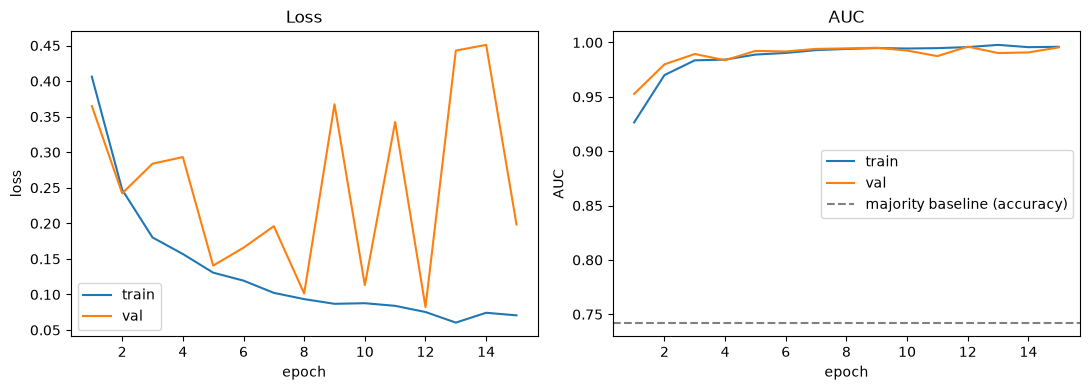

In [5]:
import matplotlib.pyplot as plt

train_hist, val_hist = history["train"], history["val"]
epochs_ran = [h["epoch"] for h in train_hist]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs_ran, [h["loss"] for h in train_hist], label="train")
axes[0].plot(epochs_ran, [h["loss"] for h in val_hist], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
axes[0].set_title("Loss")

axes[1].plot(epochs_ran, [h["auc"] for h in train_hist], label="train")
axes[1].plot(epochs_ran, [h["auc"] for h in val_hist], label="val")
axes[1].axhline(val_hist[0]["majority_baseline_accuracy"], color="gray",
                linestyle="--", label="majority baseline (accuracy)")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("AUC"); axes[1].legend()
axes[1].set_title("AUC")
plt.tight_layout(); plt.show()

## 5. Final evaluation on the test split

Reminder from the EDA: the test split has a different class balance (62.5% pneumonia) than train/val (~74%), so this is the real check of whether the model generalizes rather than just memorizing the majority class.

In [6]:
test_result = evaluate_on_test(model, loaders, spec, device,
                               out_dir="../results",
                               run_name="simple_cnn_pneumoniamnist")
test_result

[simple_cnn_pneumoniamnist] TEST metrics: EvalResult(task=binary-class, accuracy=0.8654, balanced_accuracy=0.8248, auc=0.9681, f1=0.9016, sensitivity=0.9872, specificity=0.6624, majority_baseline_accuracy=0.6250)


EvalResult(task=binary-class, accuracy=0.8654, balanced_accuracy=0.8248, auc=0.9681, f1=0.9016, sensitivity=0.9872, specificity=0.6624, majority_baseline_accuracy=0.6250)

## 6. Confusion matrix

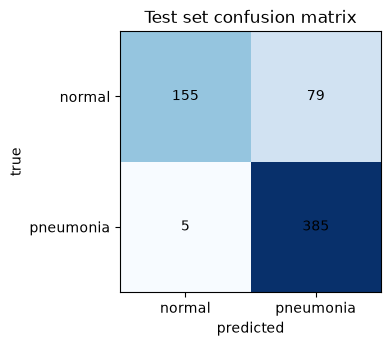

In [7]:
import numpy as np

cm = test_result.confusion
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")
labels = [spec.labels[str(c)] for c in range(spec.n_classes)]
ax.set_xticks(range(spec.n_classes)); ax.set_xticklabels(labels)
ax.set_yticks(range(spec.n_classes)); ax.set_yticklabels(labels)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Test set confusion matrix")
plt.tight_layout(); plt.show()

## 7. Observations

_Write your conclusions here: did the model beat the majority-class baseline? How far apart are validation and test AUC, given their different class balance? Does the confusion matrix suggest a bias toward one class?_